# A1. Clustering the MONDE⋅T Dataset per Amino Acid Similarity

input file: _updated_to_1000_PDB_described_protein_2026_04_Apr.csv_ (internal)

input file: _MONDE⋅T.csv_ (**download from the database tab on the webserver**) 

The following code provides SMILES and SMARTS to use in substructure searches to cluster the MONDE⋅T dataset by **chemical type** or by **canonical amino acid similarity**. By chemical type, L-, D-, β-, γ- or small cap molecule (<10 atoms, smaller than glycine) is meant. The substructure search works as follows (i) defining the pattern from an allowing SMARTS template, (ii) loading in the data as dataframe, (iii) iterating through the dataframe and quering each non-canonical SMILES against the SMARTS template. 

Optional: (iv) For the canonical amino acid parent, a non-canonical SMILES upon match is removed from the unmatched set to allow a unique 1:1-matching with a parent (e.g. tyrosine derivate should not also match phenylalanine). The hierarchy of substructure searched goes:

* Trp - Tyr - Phe
* His - Lys - Arg - Ile - Leu - Met - Pro
* Lys - Gln - Asn
* Glu - Asp
* Cys - Thr - Val
* Ala - Ser
* Gly

<span style="color:red">To customize: Change any line that I commented with `# CHANGE YOUR ...` :)  </span>

<span style="color:red">At the bottom: An example, of how to combine queries of your interest to download a customized, filtered dataset. </span>

output file: _mondet-2026-Apr-Waldherr-Freimann-noncanonical-classes.csv_

In [10]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdMolEnumerator
from rdkit.Chem import rdTautomerQuery
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.drawOptions.minFontSize = 10
Draw.SetComicMode(IPythonConsole.drawOptions)
from rdkit.Chem import rdDepictor
rdDepictor.SetPreferCoordGen(True)
import rdkit

In [13]:
ncaa_df = pd.read_csv("MONDE⋅T.csv", sep=",")           # read in the dataset, downloadable from website
ncaa_df = ncaa_df[['SMILES', 'ID', 'entity_count']]     
ncaa_df

## a) Classification by type

Classification by searching against L, D, α, β, γ, halogen, cap substructure. Cap search is different, in that we only search for atomic count less tan glycine not a given substructure. **~** matches any binding type (-,= in backbone allowed) while **[!#7]** means anything but ! atom number 7 = nitrogen.

<span style="color:red">To customize: Change any line that I commented with `# CHANGE YOUR ...` :) </span>

In [15]:
#####################################################
# Definition of SMARTS for L, D, Ester, etc. search #
#####################################################

L_list = []
D_list = []
beta_list = []
gamma_list = []

L_smarts = '[NX3,NX4+][C@@H]([*])[CX3](=[OX1])[OX2H,OX1-]'
D_smarts = '[NX3,NX4+][C@H]([*])[CX3](=[OX1])[OX2H,OX1-]' 
alpha_smarts = '[NX2,NX3+][CH]([*])[CX3](=[OX1])[OX2H,OX1-]' 
beta_smarts =  '[NH2,NH3+]~[CH2,CH]~C~C(=[OX1])[OX2H,OX1-]' 
gamma_smarts = '[NH2,NH3+]~[CH2,CH]~C~C~C(=[OX1])[OX2H,OX1-]'     

ester = '[!#7][CX3](=[OX1])[OX2][C;!#7]'
halogen = '[F,Cl,I,Br]'
# ...
# DEFINE ANY OTHER QUERY STRING OF YOUR INTEREST

total_liste = []

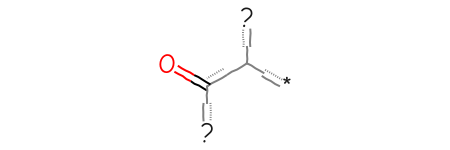

In [16]:
Chem.MolFromSmarts(D_smarts)                           # CHANGE YOUR QUERY STRING HERE, CHECK IT IS YOUR SUBSTRUCTURE

In [ ]:
###################################################################
# iterate over all SMARTS to find those ncAAs which match a, b, y #
###################################################################

matching_dict = {}
mol_matching_dict = {}

aa_qry = Chem.MolFromSmarts(D_smarts)                    # CHANGE YOUR QUERY STRING HERE
aa_matching = []
mol_matching = []

for SMILES, ID in zip(ncaa_df['SMILES'], ncaa_df['ID']):

  #  if ID not in total_liste:
   #     print(ID, SMILES)

    try:
        mol = Chem.MolFromSmiles(SMILES)
        
        if mol.HasSubstructMatch(aa_qry, useChirality=True): # useChirality=False
            
            aa_matching.append(ID)
            mol_matching.append(mol)
            # total_liste.append(ID)
    except:
        print('Problem of valence, not parsed: ', ID)  # A1IPL, A1ITS, WGB, 2AS create problems


#####################################
# SANITY CHECKS                     #
#####################################

print('\nAmounts:', len(aa_matching))
D_list = aa_matching                                   # CHANGE YOUR SAVE LIST (SEE CELL ABOVE) HERE, IF YOU WANT TO SAVE RESULT
#print('YWF' in aa_matching)                           # OPTIONAL: check if a specific ncAA (positive / negative control) was matched   

## b) Seach by size

Matches non-canonical amino acids of a specific size.

<span style="color:red">To customize: Change any line that I commented with `# CHANGE YOUR ...` :) </span>

In [ ]:
#################################################### 
# get <10 atoms (smaller than glycine) components  #
####################################################

caps = []

for SMILES, ID in zip(ncaa_df['SMILES'], ncaa_df['ID']):

    try:
        mol = Chem.MolFromSmiles(SMILES)
        
        if mol.GetNumAtoms(onlyExplicit=False) < 10:   # CHANGE YOUR SIZE OF INTEREST AND IF SMALLER OR LARGER HERE
            
            caps.append(ID)
            
    except:
        print('Problem of valence, not parsed: ', ID)  # A1IPL, A1ITS, WGB, 2AS create problems

print('\ncaps: (<10 atoms)', len(caps))                # OPTIONAL (FUNCTIONALLY NO DIFFERENCE): change to correct atom count here
print(caps)

For reference:

Length of canonical amino acids:
* ALA 13 atoms
* ARG 27
* ASN 17
* ASP 16
* CYS 14
* GLN 20
* GLU 19
* GLY 10
* HIS 21
* ILE 22
* LEU 22
* LYS 25
* MET 20
* PHE 23
* PRO 17
* SER 14
* THR 17
* TRP 27
* TYR 24
* VAL 19

## c) Classification by canonical amino acid

* [X] search the set (stereochemically insensitive) for every amino acid and save to a dictionary of lists
* [X] cut down the lists to filter unique sets (e.g. Ala-list should not be contained in Tyr-list)
* [X] make a list of those which fit nothing
* [X] check if everything was covered

Helpful for the work with sets: https://www.cheat-sheets.org/saved-copy/Python-Set-Methods-Cheat-Sheet.20210604.pdf

Helpful to work with SMARTS: https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html

### Define canonical SMARTS

<span style="color:red">Tip: This search hierarchy and these SMARTS were the best we could find to cleanly apply a SMILES matching to the canonical amino acid set and can be recommended.</span>
* Trp - Tyr - Phe
* His - Lys - Arg - Ile - Leu - Met - Pro
* Gln - Asn
* Glu - Asp
* Cys - Thr - Val
* Ala - Ser
* Gly

In [20]:
canonicalAAs = ['ALA', 'ARG', 'ASN', 'ASP', 'CYS', 'GLN', 'GLU', 'GLY', 'HIS', 'ILE', 'LEU', 'LYS', 'MET', 'PHE', 'PRO', 'SER', 'THR', 'TRP', 'TYR', 'VAL']

# SMILES as positive controls for substructure search

canonicalAA_smiles = ['C[C@@H](C(=O)O)N', 'C(C[C@@H](C(=O)O)N)CNC(=[NH2+])N', 
                      'C([C@@H](C(=O)O)N)C(=O)N', 'C([C@@H](C(=O)O)N)C(=O)O',
                      'C([C@@H](C(=O)O)N)S', 'C(CC(=O)N)[C@@H](C(=O)O)N', 'C(CC(=O)O)[C@@H](C(=O)O)N',
                      'C(C(=O)O)N', 'c1c([nH+]c[nH]1)C[C@@H](C(=O)O)N',
                      'CC[C@H](C)[C@@H](C(=O)O)N', 'CC(C)C[C@@H](C(=O)O)N', 'C(CC[NH3+])C[C@@H](C(=O)O)N',
                      'CSCC[C@@H](C(=O)O)N', 'c1ccc(cc1)C[C@@H](C(=O)O)N', 'C1C[C@H](NC1)C(=O)O',
                      'C([C@@H](C(=O)O)N)O', 'C[C@H]([C@@H](C(=O)O)N)O',
                      'c1ccc2c(c1)c(c[nH]2)C[C@@H](C(=O)O)N', 'c1cc(ccc1C[C@@H](C(=O)O)N)O', 'CC(C)[C@@H](C(=O)O)N']

# SMARTS to apply as query patterns
# CHANGE HERE: These are our set to recommend! (Often iteratively improved, manually checked on the 2026 dataset.) Change, if you search for specific charge states or modified sites, etc.

canonicalAA_dict = {'TRP': {'SMARTS': 'c1ccc2c(c1)c(c[nH]2)C[C@@H](C(=O)O)N'},
                      'TYR': {'SMARTS': 'c1cc(ccc1C[C@@H](C(=O)O)N)O'},
                      'PHE': {'SMARTS': 'c1ccc(cc1)C[C@@H](C(=O)O)N'},
                      'HIS': {'SMARTS': 'c1c([n]c[n]1)C[C@@H](C(=O)O)N'},
                      'LYS': {'SMARTS': 'C(CC[N])C[C@@H](C(=O)O)N'},
                      'ARG': {'SMARTS': 'C(C[C@@H](C(=O)O)N)CNC(=[N])N'},
                      'ILE': {'SMARTS': 'CC[C@H](C)[C@@H](C(=O)O)N'},
                      'LEU': {'SMARTS': 'CC(C)C[C@@H](C(=O)O)N'},
                      'MET': {'SMARTS': 'CSCC[C@@H](C(=O)O)N'},
                      'PRO': {'SMARTS': 'C1C[C@H](NC1)C(=O)O'},
                      'GLN': {'SMARTS': 'C(CC(=O)N)[C@@H](C(=O)O)N'},
                      'GLU': {'SMARTS': 'C(CC(=O)O)[C@@H](C(=O)O)N'},
                      'ASN': {'SMARTS': 'C([C@@H](C(=O)O)N)C(=O)N'},
                      'ASP': {'SMARTS': 'C([C@@H](C(=O)O)N)C(=O)O'},
                      'CYS': {'SMARTS': 'C([C@@H](C(=O)O)N)S'},
                      'THR': {'SMARTS': 'C[C@H]([C@@H](C(=O)O)N)O'},
                      'VAL': {'SMARTS': 'CC(C)[C@@H](C(=O)O)N'},
                      'SER': {'SMARTS': 'C([C@@H](C(=O)O)N)O'},
                      'ALA': {'SMARTS': 'C[C@@H](C(=O)O)N'},
                      'chromophore': {'SMARTS': 'C1~[N,n]~C~C(=O)~[N,n]~1'}, 
                      'GLY': {'SMARTS': 'C(C(=O)O)N'}}

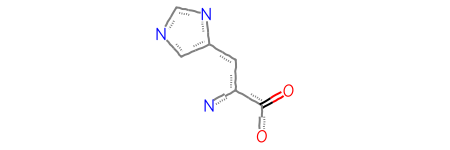

In [21]:
Chem.MolFromSmarts('c1c([n]c[n]1)C[C@@H](C(=O)O)N')     # CHANGE YOUR QUERY STRING HERE, IF YOU WANT TO ADD A DIFFERENT SUBSTRUCTURE

In [ ]:
#################################################
# DEF: add row to the dataframe                 #
#################################################

def add_row(df, ID, SMILES, entity_count, parent):
    
    new_row = pd.DataFrame({"ID": [ID],
                            "SMILES": [SMILES],
                            "entity_count": [entity_count],
                            "parent": [parent]})
    
    df = pd.concat([df, new_row], ignore_index=True)

    return df 

In [ ]:
###################################################
# DEF: canonical parent query                     #
###################################################

def canonical_query(canonicalAA, canonicalAA_dict, ncaa_df, negative_examples, ncaa_classes_df):

    # ncaa_classes_df = to store the data
    # canonicalAA = ID (e.g. ALA)
    # canonicalAA_dict = master dict with ['ALA']: {'SMARTS': ..., 'aa_matching': ..., 'mol_matching': ...}

    aa_smarts = canonicalAA_dict[canonicalAA]['SMARTS']    # get the SMARTS saved to it
    aa_qry = Chem.MolFromSmarts(aa_smarts)   #  make a query molecule from it
    
    aa_matching = []
    mol_matching = []

    for SMILES, ID, entity_count in zip(ncaa_df['SMILES'], ncaa_df['ID'], ncaa_df['entity_count']):

        if ID in negative_examples:
            continue

        else:
            
            try:
                mol = Chem.MolFromSmiles(SMILES)
                
                if mol.HasSubstructMatch(aa_qry, useChirality=False): # CHANGE HERE, IF YOU WANT TO NOT MATCH D-amino acids to an L-canonical parent

                    aa_matching.append(ID)
                    mol_matching.append(mol)
                    negative_examples.append(ID)    # save this to not use it for another amino acids with less priority

                    ncaa_classes_df = add_row(ncaa_classes_df, ID, SMILES, entity_count, canonicalAA)

                    if canonicalAA == "GLY":
                        print(SMILES)
                    else:
                        None
                    
            except:
                continue  # A1IPL, A1ITS, WGB, 2AS create problems

    canonicalAA_dict[f'{canonicalAA}']['aa_matching'] = aa_matching
    canonicalAA_dict[f'{canonicalAA}']['mol_matching'] = mol_matching
    canonicalAA_dict[f'{canonicalAA}']['unique_children'] = len(aa_matching)
    
    return canonicalAA_dict, negative_examples, ncaa_classes_df

In [ ]:
# iterate over all canonical AAs and find those ncAAs which match

# array to store the labels for parsing on the website
ncaa_classes_df = pd.DataFrame()
ncaa_classes_df = ncaa_classes_df.assign(**{col: '' for col in ["ID", "SMILES", "entity_count", "parent"]})

# start the run
negative_examples = []

for aa in canonicalAA_dict.keys():
                                                                                     # MAKE SURE ↓ LOADED AT VERY TOP OF NOTEBOOK :)
    canonicalAA_dict, negative_examples, ncaa_classes_df = canonical_query(aa, canonicalAA_dict, ncaa_df, negative_examples, ncaa_classes_df)

    # sanity check if it finds itself
    if aa in canonicalAA_dict[f'{aa}']['aa_matching']:
        print(f'{aa} has found itself')
    elif aa not in canonicalAA_dict[f'{aa}']['aa_matching']:
        print(f'! {aa} has NOT FOUND itself')

In [ ]:
# draw the subsets

for aa_mol in canonicalAA_dict.keys():
    print(f"{aa_mol} MATCHES {len(canonicalAA_dict[aa_mol]['mol_matching'])}")
    img = Draw.MolsToGridImage(canonicalAA_dict[aa_mol]['mol_matching'][:50], molsPerRow=10, subImgSize=(100,100))
    display(img)

In [ ]:
# save the subsets

ncaa_classes_df.to_csv("mondet-2026-Apr-Waldherr-Freimann-noncanonical-classes.csv", sep=";")

In [ ]:
# OPTIONAL: make a specific dataframe with lists

# canonical_found_df = pd.DataFrame(canonicalAA_dict)
# canonical_found_df.sort_index(axis=1, inplace=True)
# canonical_found_df.drop('mol_matching', axis=0, inplace=True)
# canonical_found_df.to_csv("clustered_per_canonical.csv", sep=";")
# canonical_found_df

## d) Example: Combine your queries of interest

This example shows how to (i) filter for a specific size of chemical components (here: span of canonical amino acids), and (ii) filter for a specific backbone type of amino acid (here: canonical L-α-amino acid type).

Helpful for understanding and customizing substructure search: https://greglandrum.github.io/rdkit-blog/posts/2021-08-03-generalized-substructure-search.html

Helpful to work with SMARTS: https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html

In [ ]:
########################################################################
# Get >10 atoms and <27 atoms (between canonical size, +H) components  #
########################################################################

canonical_size_similar = {}

for SMILES, ID, entity_count in zip(ncaa_df['SMILES'], ncaa_df['ID'], ncaa_df['entity_count']):

    try:
        mol = Chem.MolFromSmiles(SMILES)
        
        if (mol.GetNumAtoms(onlyExplicit=False) >= 10) and (mol.GetNumAtoms(onlyExplicit=False) <= 27):
            
            canonical_size_similar[ID] = {'SMILES': SMILES, 'num_atoms': mol.GetNumAtoms(onlyExplicit=False),'entity_count': entity_count}
            
    except:
        print('Problem of valence, not parsed: ', ID)  # A1IPL, A1ITS, WGB, 2AS create problems

print('IDs similar in size to canonical span (incl. H: >= 10, <=27):', len(canonical_size_similar))
canonical_size_similar_df = pd.DataFrame.from_dict(canonical_size_similar, orient='index')
canonical_size_similar_df.to_csv("total-27-atoms.csv", sep=";")


####################################
# Find L-α-amino acid candidates   #
####################################

L_smarts = '[NX3,NX4+][C@@H]([*])[CX3](=[OX1])[OX2H,OX1-]'

aa_qry = Chem.MolFromSmarts(L_smarts)

canonical_size_similar = {}

for SMILES, ID, entity_count in zip(canonical_size_similar['SMILES'], canonical_size_similar.index, canonical_size_similar['entity_count']):

    print(SMILES, ID, entity_count)

    try:
        mol = Chem.MolFromSmiles(SMILES)
        
        if mol.HasSubstructMatch(aa_qry, useChirality=False):

            canonical_size_similar[ID] = {'SMILES': SMILES, 'num_atoms': mol.GetNumAtoms(onlyExplicit=False),'entity_count': entity_count, 'aa-acid': 'likely'}
            
    except:
        print('Problem of valence, not parsed: ', ID)  # A1IPL, A1ITS, WGB, 2AS create problems

print('AA likely: IDs similar in size to canonical span and alpha-amino acid (>= 10, <=27, aa search):', len(canonical_size_similar))
canonical_size_similar_df = pd.DataFrame.from_dict(canonical_size_similar, orient='index')
canonical_size_similar.to_csv("total-27-atoms-ALPHA-AMINO-ACID.csv", sep=";")